# Çoklu Enstrüman Tanıma Projesi — Veri Keşfi ve Ön İşleme

## 1. Problem Tanımı
Bir müzik kaydında çalan baskın enstrümanın otomatik tanınması, müzik bilgi erişimi (Music Information Retrieval) alanının temel problemlerinden biridir. Bu projede 3 saniyelik ses kayıtlarını girdi olarak alıp, kayıtta baskın olan enstrümanı 11 sınıftan biri olarak tahmin eden bir derin öğrenme modeli geliştirilmiştir. Girdi ham ses dalga formu, hedef çıktı ise sınıf etiketidir (örneğin piyano, keman, insan sesi). Böyle bir sistem otomatik müzik etiketleme, çalma listesi üretimi ve büyük müzik arşivlerinde arama gibi gerçek dünya uygulamalarında kullanılabilir. Manuel etiketlemenin ölçeklenemediği durumlarda otomatik enstrüman tanıma, arşivlerin hızlı ve tutarlı biçimde indekslenmesini sağlar.

## 2. Veri Seti Tanıtımı
- **Kaynak:** IRMAS (Instrument Recognition in Musical Audio Signals), Music Technology Group (MTG), Universitat Pompeu Fabra (UPF).
- **Bağlantı:** https://www.upf.edu/web/mtg/irmas — Zenodo DOI: 10.5281/zenodo.1290750
- **Referans:** Bosch, J. J., Janer, J., Fuhrmann, F., & Herrera, P. (2012). *A Comparison of Sound Segregation Techniques for Predominant Instrument Recognition in Musical Audio Signals*, ISMIR.
- **Lisans:** CC BY-NC-SA 3.0 — yalnızca ticari olmayan kullanım için ücretsizdir; yeniden dağıtılamaz ve değiştirilemez.
- **Yapı:** 6705 adet 3 saniyelik, 16-bit, 44.1 kHz WAV kaydı; 11 enstrüman sınıfı.
- **Hedef değişken:** Dosyanın bulunduğu klasör adı (birincil baskın enstrüman etiketi).
- **Not:** IRMAS kayıtları çok etiketlidir (örn. `[gac][cla]...` = birincil akustik gitar + ikincil klarnet). Bu projede yalnızca **birincil (klasör) etiketi** kullanılmıştır.
- **Sınıf dengesizliği:** Sınıf başına örnek sayısı 388 (çello) ile 778 (insan sesi) arasında değişmektedir (yaklaşık 2:1 oran).

Örnekleme Frekansı (Sample Rate): 44100 Hz
Toplam Veri Noktası: 132299
Sesin Süresi: 3.00 saniye


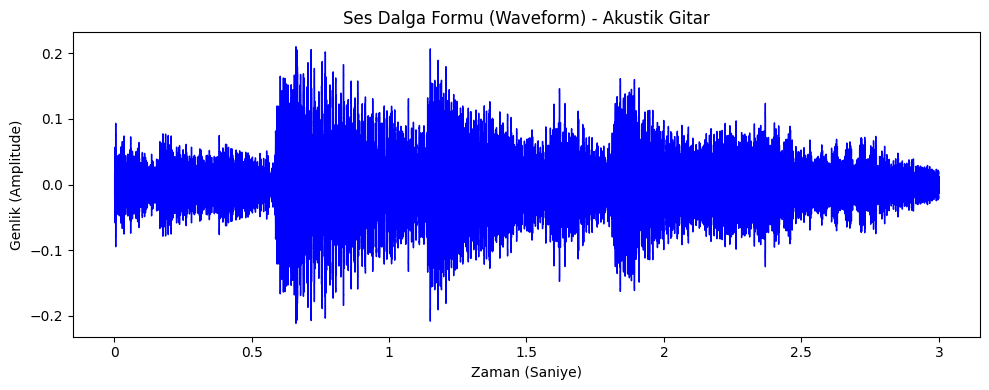

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

ses_yolu = "IRMAS-TrainingData/gac/[gac][cla]0518__3.wav"

y, sr = librosa.load(ses_yolu, sr=None, mono=True)

print(f"Örnekleme Frekansı (Sample Rate): {sr} Hz")
print(f"Toplam Veri Noktası: {len(y)}")
print(f"Sesin Süresi: {len(y) / sr:.2f} saniye")
    
plt.figure(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr, color="blue")
plt.title('Ses Dalga Formu (Waveform) - Akustik Gitar')
plt.xlabel('Zaman (Saniye)')
plt.ylabel('Genlik (Amplitude)')
plt.tight_layout()
plt.show()

**Gözlem:** Akustik gitar kaydı 44.1 kHz örnekleme frekansında ve 3 saniye (132.299 veri noktası) uzunluğundadır. Dalga formu, enstrümana özgü genlik değişimlerini (nota başlangıçları ve sönümlenmeler) göstermektedir; ancak tek başına dalga formundan enstrüman ayrımı yapmak zordur. Bu nedenle frekans içeriğini gösteren spektral temsillere ihtiyaç vardır.

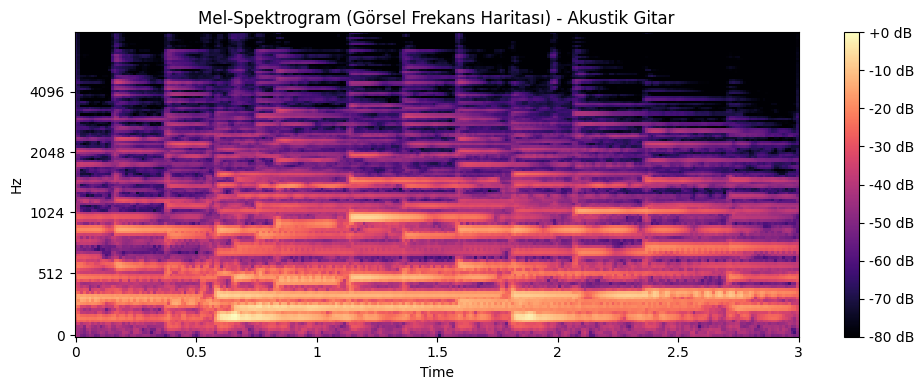

Mel-Spektrogram Matris Boyutu: (128, 259)


In [3]:
mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)

mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spectrogram_db, x_axis='time', y_axis='mel', sr=sr, fmax=8000, cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-Spektrogram (Görsel Frekans Haritası) - Akustik Gitar')
plt.tight_layout()
plt.show()

print(f"Mel-Spektrogram Matris Boyutu: {mel_spectrogram_db.shape}")

**Gözlem:** Mel-spektrogram, sesin zaman-frekans temsilini verir ve enstrümanları ayırt eden tını (timbre) bilgisini taşır: harmonik çizgiler, formantlar ve gürültü bileşenleri. Akustik gitarda temel frekans ve harmonikler belirgin yatay çizgiler halinde görülmektedir. Bu matris (128 mel bandı × 259 zaman karesi), CNN modeli için bir "görüntü" olarak kullanılacaktır. Tüm kayıtlar 128×130 boyutuna getirilerek (kırpma/dolgu) modele sabit boyutlu girdi sağlanır.

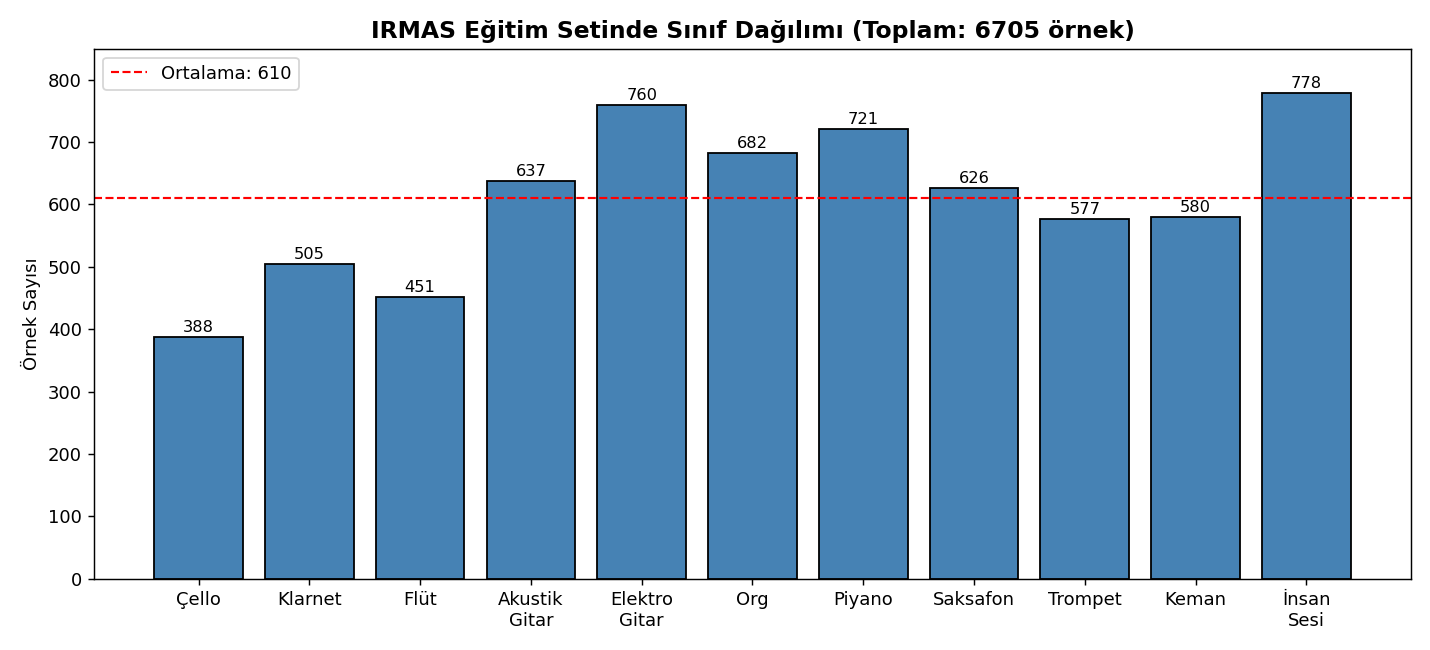

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt

VERI_KLASORU = "IRMAS-TrainingData"
enstruman_isimleri = {
    'cel': 'Çello', 'cla': 'Klarnet', 'flu': 'Flüt', 'gac': 'Akustik\nGitar',
    'gel': 'Elektro\nGitar', 'org': 'Org', 'pia': 'Piyano', 'sax': 'Saksafon',
    'tru': 'Trompet', 'vio': 'Keman', 'voi': 'İnsan\nSesi'
}

siniflar = sorted([d for d in os.listdir(VERI_KLASORU) if os.path.isdir(os.path.join(VERI_KLASORU, d))])
sayilar = [len([f for f in os.listdir(os.path.join(VERI_KLASORU, s)) if f.endswith('.wav')]) for s in siniflar]
isimler = [enstruman_isimleri[s] for s in siniflar]

plt.figure(figsize=(11, 5))
bars = plt.bar(isimler, sayilar, color='steelblue', edgecolor='black')
for b, s in zip(bars, sayilar):
    plt.text(b.get_x() + b.get_width()/2, s + 8, str(s), ha='center', fontsize=9)
plt.title('IRMAS Eğitim Setinde Sınıf Dağılımı (Toplam: 6705 örnek)', fontsize=13, fontweight='bold')
plt.ylabel('Örnek Sayısı')
plt.ylim(0, 850)
plt.axhline(np.mean(sayilar), color='red', linestyle='--', linewidth=1.2, label=f'Ortalama: {np.mean(sayilar):.0f}')
plt.legend()
plt.tight_layout()
plt.show()

**Gözlem:** Sınıflar arasında belirgin olmayan ama hissedilir bir dengesizlik vardır: en az örnek çelloda (388), en çok örnek insan sesinde (778) bulunmaktadır (yaklaşık 2:1). Elektro gitar, piyano, org ve insan sesi ortalamanın üzerinde; çello, flüt ve klarnet ortalamanın altındadır. Bu dengesizlik, modelin az örnekli sınıflarda (çello, flüt, klarnet) daha düşük başarı göstermesine katkıda bulunabilir; sınıf ağırlıkları (class weights) veya hedefli veri artırma ile telafi edilebilir.

In [1]:
!pip install tqdm scikit-learn

     ---------------------------------------- 0.0/78.4 kB ? eta -:--:--
     -------------- ----------------------- 30.7/78.4 kB 660.6 kB/s eta 0:00:01
     -------------- ----------------------- 30.7/78.4 kB 660.6 kB/s eta 0:00:01
     ---------------------------------- --- 71.7/78.4 kB 563.7 kB/s eta 0:00:01
     -------------------------------------- 78.4/78.4 kB 625.1 kB/s eta 0:00:00



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import librosa
from tqdm import tqdm


VERI_KLASORU = "IRMAS-TrainingData"
HEDEF_GENISLIK = 130  
N_MELS = 128

X_data = [] 
y_data = [] 

siniflar = [d for d in os.listdir(VERI_KLASORU) if os.path.isdir(os.path.join(VERI_KLASORU, d))]
print(f"Bulunan Sınıflar: {siniflar}")

for sinif in siniflar:
    sinif_yolu = os.path.join(VERI_KLASORU, sinif)
    ses_dosyalari = [f for f in os.listdir(sinif_yolu) if f.endswith('.wav')]
    
    print(f"\nİşleniyor: {sinif} sınıfı ({len(ses_dosyalari)} dosya)")
    
    for dosya in tqdm(ses_dosyalari):
        dosya_yolu = os.path.join(sinif_yolu, dosya)
        
        try:
            y, sr = librosa.load(dosya_yolu, sr=None, mono=True)
            mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS, fmax=8000)
            mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
            
            mevcut_genislik = mel_spec_db.shape[1]
            if mevcut_genislik < HEDEF_GENISLIK:
                pad_width = HEDEF_GENISLIK - mevcut_genislik
                mel_spec_db = np.pad(mel_spec_db, pad_width=((0, 0), (0, pad_width)), mode='constant')
            elif mevcut_genislik > HEDEF_GENISLIK:
                mel_spec_db = mel_spec_db[:, :HEDEF_GENISLIK]
                
            X_data.append(mel_spec_db)
            y_data.append(sinif)
            
        except Exception as e:
            print(f"Hata oluşan dosya: {dosya} - {e}")

X = np.array(X_data)
y = np.array(y_data)

print("\n--- İŞLEM TAMAMLANDI ---")
print(f"Toplam İşlenen Veri (X): {X.shape}") 
print(f"Toplam Etiket Sayısı (y): {y.shape}")

np.save("X_veri.npy", X)
np.save("y_etiket.npy", y)
print("Veriler başarıyla X_veri.npy ve y_etiket.npy olarak diske kaydedildi.")

Bulunan Sınıflar: ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']

İşleniyor: cel sınıfı (388 dosya)


100%|████████████████████████████████████████████████████████████████████████████████| 388/388 [00:11<00:00, 32.83it/s]



İşleniyor: cla sınıfı (505 dosya)


100%|████████████████████████████████████████████████████████████████████████████████| 505/505 [00:09<00:00, 53.63it/s]



İşleniyor: flu sınıfı (451 dosya)


...


İşleniyor: vio sınıfı (580 dosya)


100%|████████████████████████████████████████████████████████████████████████████████| 580/580 [00:11<00:00, 51.51it/s]



İşleniyor: voi sınıfı (778 dosya)


100%|████████████████████████████████████████████████████████████████████████████████| 778/778 [00:15<00:00, 51.09it/s]



--- İŞLEM TAMAMLANDI ---
Toplam İşlenen Veri (X): (6705, 128, 130)
Toplam Etiket Sayısı (y): (6705,)
Veriler başarıyla X_veri.npy ve y_etiket.npy olarak diske kaydedildi.


**Özet:** Tüm 6705 kayıt işlenerek mel-spektrogram verisi `X_veri.npy` (6705 × 128 × 130) ve etiketler `y_etiket.npy` olarak kaydedilmiştir. Ön işleme adımları: mono'ya çevirme, mel-spektrogram çıkarımı (128 mel bandı, fmax = 8000 Hz), dB dönüşümü ve sabit genişliğe getirme (130 zaman karesi; kısa kayıtlar sıfır ile doldurulur, uzun kayıtlar kırpılır). Ses verisinde eksik değer bulunmaz; aykırı değer analizi yerine tüm kayıtlar aynı temsil biçimine dönüştürülmüştür.